# Hyperspectral pipeline with an EMIT image
Explore the EMIT hyperspectral cube → spectra → scatter plots → PCA → t-SNE → k-means → classification map.

The scene (EMIT, 17 Feb 2025, southern India) is in the Kaggle dataset **EMIT_60233**.
Data: Green, R. (2022). *EMIT L2A Estimated Surface Reflectance and Uncertainty and Masks 60 m V001*. NASA EOSDIS LP DAAC. https://doi.org/10.5067/EMIT/EMITL2ARFL.001

Runs on **Kaggle**, no NASA account needed. In the notebook editor: *Add Input* → search **EMIT_60233** → add it.


## 1. Install the extra packages and import libraries

In [5]:
!pip install -q anywidget      
import numpy as np, matplotlib.pyplot as plt, xarray as xr
import plotly.express as px, plotly.graph_objects as go, ipywidgets as w
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

## 2. Load the EMIT scene from the Kaggle dataset and display it
Reflectance file (~1.8 GB) + mask file. The mask flags pixels you shouldn't trust (cloud, water, …).

['/kaggle/input/datasets/ranjansarkar/emit-60233/EMIT_L2A_MASK_001_20260211T080401_2604206_018.nc', '/kaggle/input/datasets/ranjansarkar/emit-60233/EMIT_L2A_RFL_001_20260211T080401_2604206_018.nc']
mask layers: ['Cloud flag', 'Cirrus flag', 'Water flag', 'Spacecraft Flag', 'Dilated Cloud Flag', 'AOD550', 'H2O (g cm-2)', 'Aggregate Flag']


Text(0.5, 1.0, 'Flagged pixels (white)')

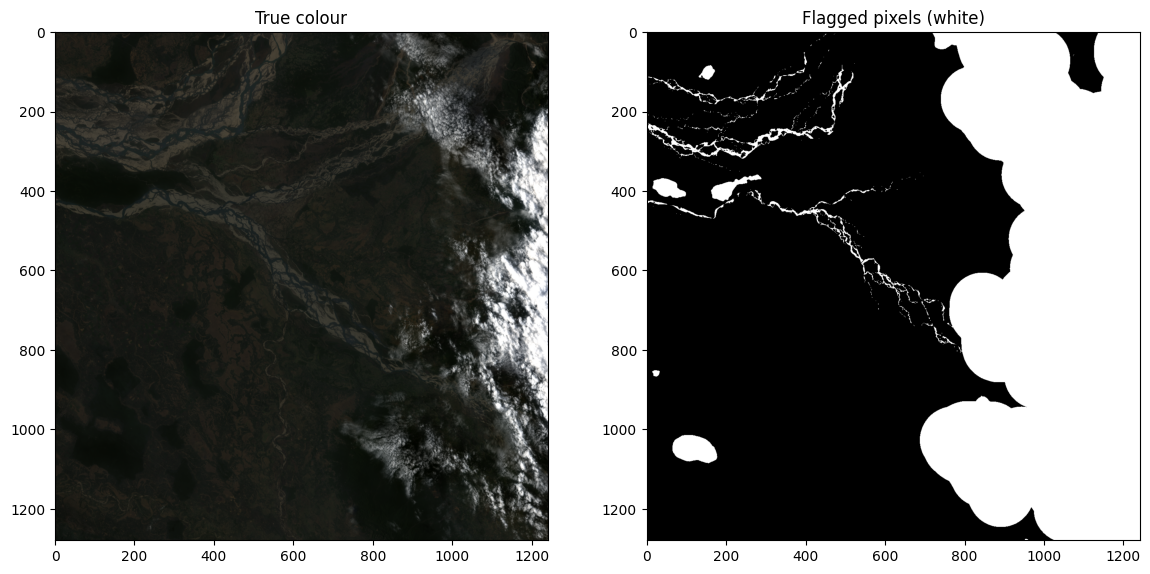

In [6]:
from glob import glob
scene = "20260211T080401_2604206_018"                                # date, time and ID in the file name
files = glob(f"/kaggle/input/**/*{scene}*.nc", recursive=True); print(files)
assert files, "No EMIT files found: add the EMIT_60233 dataset with 'Add Input' (right-hand panel)"
f      = [x for x in files if "_RFL_" in x][0]                          # reflectance file
mask_f = [x for x in files if "_MASK_" in x][0]                         # mask file

ds = xr.open_dataset(f)                                          # the reflectance cube + metadata
bp = xr.open_dataset(f, group="sensor_band_parameters")          # wavelengths + good-band flags
good = bp.good_wavelengths.values == 1                           # drop the water-vapour absorption bands
img  = ds.reflectance[:, :, good].values                         # (rows, cols, bands)
img.clip(0, 1, out=img)                                          # fill values (-9999) -> 0
wl   = bp.wavelengths.values[good]                               # nm
band = lambda nm: np.argmin(abs(wl - nm))                        # wavelength (nm) -> band index
stretch = lambda x: np.clip(x / np.percentile(x, 99), 0, 1)      # brighten an image for display

mk     = xr.open_dataset(mask_f)
mnames = list(xr.open_dataset(mask_f, group="sensor_band_parameters").mask_bands.values)
print("mask layers:", mnames)
flag   = mk["mask"].values[:, :, mnames.index("Aggregate Flag")]   # 1 = cloud / water / bad pixel

plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1); plt.imshow(stretch(img[:, :, [band(650), band(560), band(470)]])); plt.title("True colour")
plt.subplot(1, 2, 2); plt.imshow(flag, cmap="gray"); plt.title("Flagged pixels (white)")

## 3. Get to know the image cube
`img` is a 3-D NumPy array: **(rows, columns, bands)**. Every pixel `img[row, col, :]` is a full spectrum.

In [7]:
print(f"number of rows    = {img.shape[0]}")
print(f"number of columns = {img.shape[1]}")
print(f"number of bands   = {img.shape[2]}")
print(wl)
ds          # the file's metadata

number of rows    = 1280
number of columns = 1242
number of bands   = 255
[ 380.85788  388.26147  395.6681   403.0777   410.49026  417.90585
  425.32443  432.745    440.16953  447.5951   455.0226   462.45114
  469.8827   477.3152   484.7497   492.1852   499.6237   507.0622
  514.5027   521.9432   529.3856   536.8291   544.27356  551.719
  559.16644  566.6139   574.06134  581.5108   588.9602   596.41064
  603.86206  611.3145   618.7669   626.22034  633.67377  641.1282
  648.5826   656.03796  663.4934   670.94977  678.4062   685.8626
  693.32     700.7774   708.2358   715.6932   723.1516   730.61096
  738.0694   745.5288   752.9882   760.4486   767.908    775.3684
  782.8298   790.2902   797.75165  805.21405  812.6754   820.13684
  827.59827  835.0597   842.5221   849.9835   857.446    864.9074
  872.3699   879.8323   887.29376  894.7562   902.2187   909.68115
  917.1436   924.6061   932.06854  939.53107  946.99255  954.455
  961.9165   969.379    976.8406   984.30206  991.7636   999.225

<xarray.Dataset> Size: 2GB
Dimensions:      (downtrack: 1280, crosstrack: 1242, bands: 285)
Dimensions without coordinates: downtrack, crosstrack, bands
Data variables:
    reflectance  (downtrack, crosstrack, bands) float32 2GB ...
Attributes: (12/37)
    ncei_template_version:             NCEI_NetCDF_Swath_Template_v2.0
    summary:                           The Earth Surface Mineral Dust Source ...
    keywords:                          Imaging Spectroscopy, minerals, EMIT, ...
    Conventions:                       CF-1.63
    sensor:                            EMIT (Earth Surface Mineral Dust Sourc...
    instrument:                        EMIT
    ...                                ...
    southernmost_latitude:             27.244149226163522
    spatialResolution:                 0.000542232520256367
    spatial_ref:                       GEOGCS["WGS 84",DATUM["WGS_1984",SPHER...
    geotransform:                      [ 9.51918961e+01  5.42232520e-04 -0.00...
    day_night_flag:                    Day
    title:                             EMIT L2A Estimated Surface Reflectance...

## 4. Display the image from three bands of your choice
Use band **indices** (0 … bands-1) or convert a wavelength with `band(nm)`. Try false colour: `band(860), band(650), band(560)`.

R = band 36 at 648.6 nm,  G = band 24 at 559.2 nm,  B = band 12 at 469.9 nm


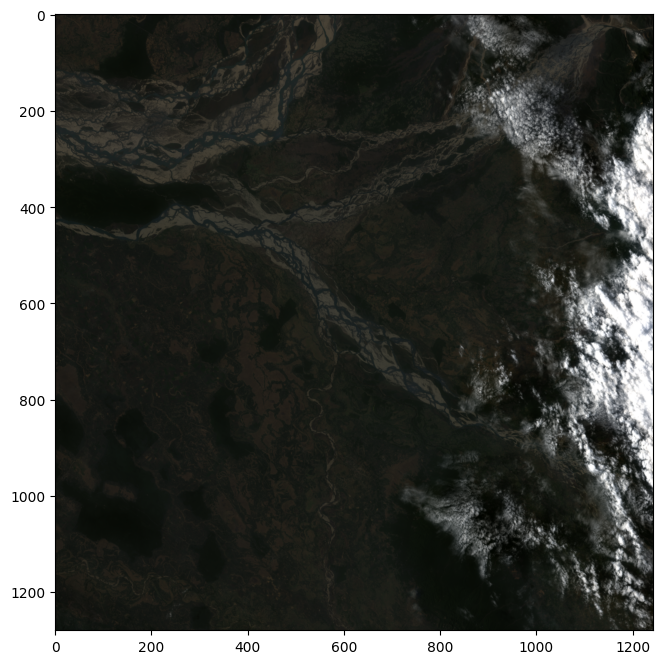

In [8]:
r, g, b = band(650), band(560), band(470)        # or plain indices, e.g. 35, 20, 10
print(f"R = band {r} at {wl[r]:.1f} nm,  G = band {g} at {wl[g]:.1f} nm,  B = band {b} at {wl[b]:.1f} nm")

plt.figure(figsize=(8, 8)); plt.imshow(stretch(img[:, :, [r, g, b]]))

## 5. Plot the spectrum of one pixel
⚠️ `img[row, col]` — **row is the y-axis, col is the x-axis**. The cross-hairs on the left show where the pixel is.

Text(0, 0.5, 'Reflectance')

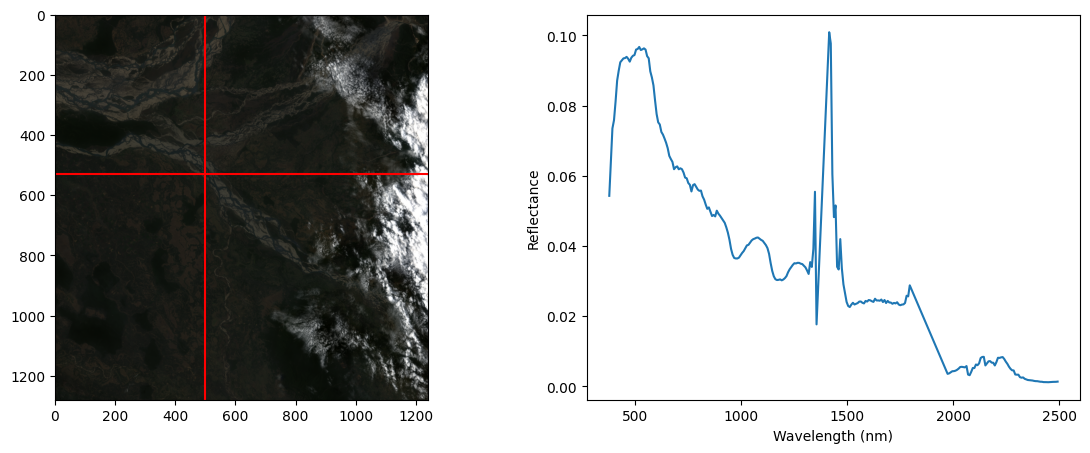

In [10]:
row, col = 528, 498
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1);
plt.imshow(stretch(img[:, :, [band(650), band(560), band(470)]]))
plt.axhline(row, color="r"); plt.axvline(col, color="r")

plt.subplot(1, 2, 2); plt.plot(wl, img[row, col, :]); 
plt.xlabel("Wavelength (nm)"); 
plt.ylabel("Reflectance")

## 6 Crop a small area and turn the cube into a table
The full scene has ~1.5 million pixels — too many for t-SNE. Pick a ~128×128 crop with a mix of land covers.
`reshape` turns the cube **(rows, cols, bands)** into a table **X = (pixels, bands)**: one row per pixel, one column per band.
This table is what every machine-learning tool below expects.

(158, 158, 255) -> (24964, 255)


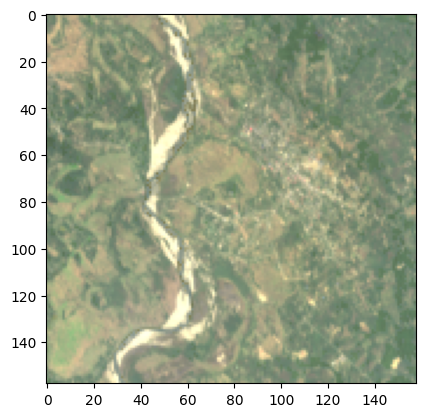

In [11]:
row0, col0, size = 880, 520, 158
cube = img[row0:row0 + size, col0:col0 + size]
X    = cube.reshape(-1, cube.shape[2])                         # (pixels, bands)
# X = cube.reshape(size * size, cube.shape[2])     #alternative way to convert into table.
print(cube.shape, "->", X.shape); plt.imshow(stretch(cube[:, :, [band(650), band(560), band(470)]]))

## * 7. 2-D scatter plot: every pixel is a point, two bands are the axes


Text(0, 0.5, '857 nm')

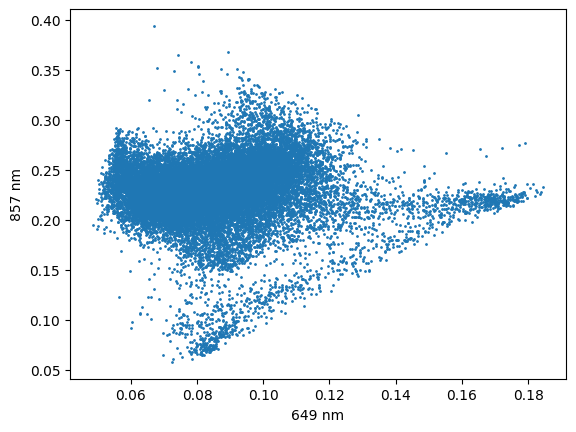

In [12]:
b1, b2 = band(650), band(860)
plt.scatter(X[:, b1], X[:, b2], s=1)
plt.xlabel(f"{wl[b1]:.0f} nm"); plt.ylabel(f"{wl[b2]:.0f} nm")

## 8. 3-D scatter plot (drag to rotate)

In [13]:
b1, b2, b3 = band(470), band(650), band(860)
px.scatter_3d(x=X[:, b1], y=X[:, b2], z=X[:, b3], height=600,
              labels=dict(x=f"{wl[b1]:.0f} nm", y=f"{wl[b2]:.0f} nm", z=f"{wl[b3]:.0f} nm")).update_traces(marker_size=1)

## 8b. 100 random pixel spectra
Notice how the curves rise and fall together: the bands are far from independent.

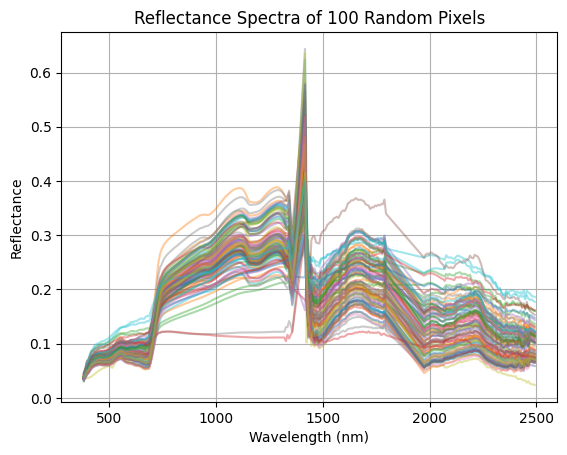

In [14]:
n = 100

# Select 100 random pixels from X
idx = np.random.choice(len(X), n, replace=False)

# Plot reflectance spectra
plt.plot(wl, X[idx].T, alpha=0.4)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance")
plt.title("Reflectance Spectra of 100 Random Pixels")
plt.grid(True)
plt.show()

## 9. The data live on far fewer dimensions than the number of bands
We have ~240 bands (the *ambient* dimension), but neighbouring bands carry almost the same information.
Left: two adjacent bands fall on a straight line. Right: band-to-band correlation — large red blocks are groups of redundant bands.

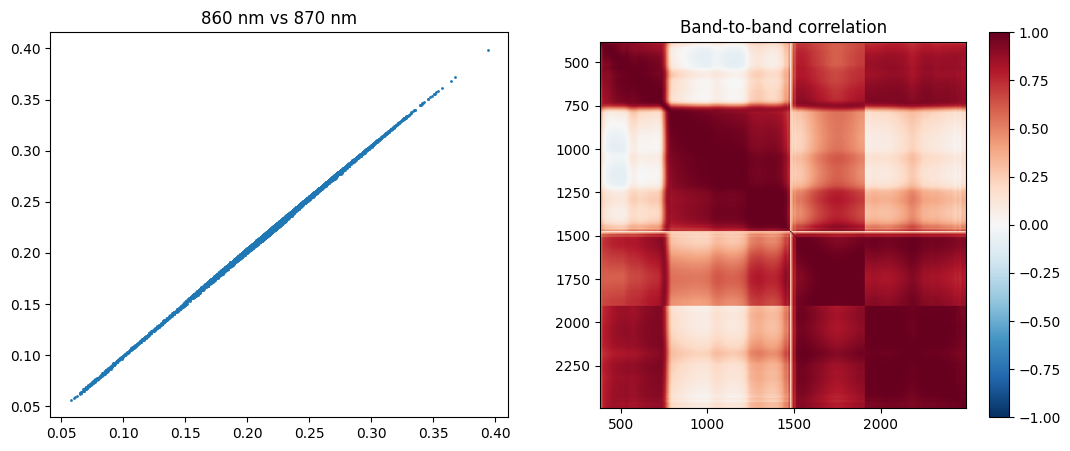

In [15]:
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1); plt.scatter(X[:, band(860)], X[:, band(870)], s=1); plt.title("860 nm vs 870 nm")
plt.subplot(1, 2, 2); plt.imshow(np.corrcoef(X.T), cmap="RdBu_r", vmin=-1, vmax=1, extent=[wl[0], wl[-1], wl[-1], wl[0]])
plt.title("Band-to-band correlation"); plt.colorbar()

## 10. PCA

In [26]:
n_pc = 50
pca = PCA(n_components=n_pc).fit(X); P = pca.transform(X)       # P = (pixels, n_pc)

## 11. Scree plot
Move `elbow` to where you think the curve flattens. How many PCs out of ~240 bands do you really need?
Comment out `plt.yscale("log")` to see the difference.

Text(0, 0.5, 'Explained variance ratio')

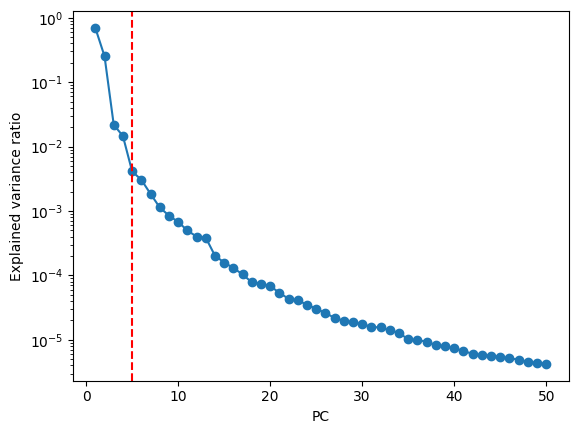

In [27]:
elbow = 5 # Although we specify this value in the beginning, but it has to be diceded based on the output of the scree plot in the nexr cell's output.
plt.plot(range(1, n_pc + 1), pca.explained_variance_ratio_, "o-")
plt.yscale("log")
plt.axvline(elbow, color="r", ls="--")
plt.xlabel("PC"); plt.ylabel("Explained variance ratio")
# print(f"The first {elbow} PCs hold {pca.explained_variance_ratio_[:elbow].sum():.2%} of the variance of {X.shape[1]} bands")

## 12. Scatter two PCs against each other
PCs are numbered from 0. Also look at a PC as an image (right).

Text(0.5, 1.0, 'PC0 as an image')

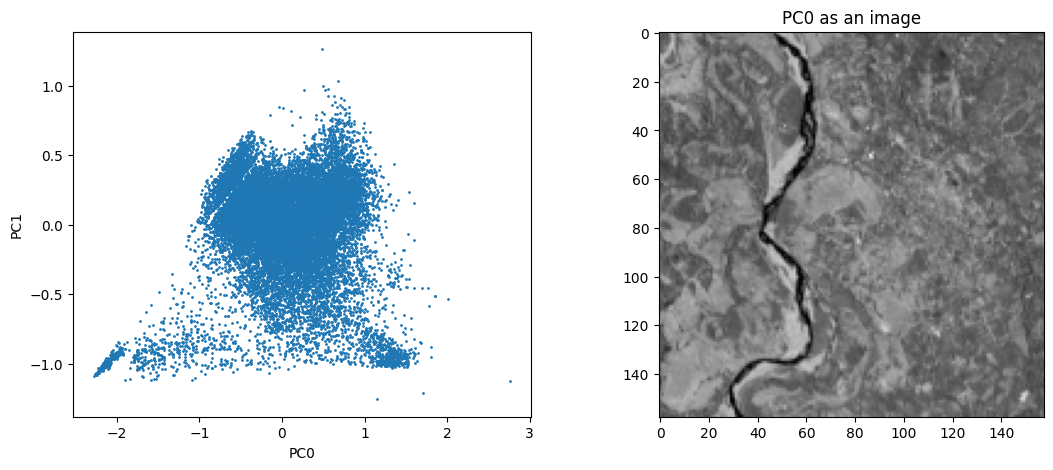

In [18]:
pc_a, pc_b = 0, 1
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1); plt.scatter(P[:, pc_a], P[:, pc_b], s=1); plt.xlabel(f"PC{pc_a}"); plt.ylabel(f"PC{pc_b}")
plt.subplot(1, 2, 2); plt.imshow(P[:, pc_a].reshape(size, size), cmap="gray"); plt.title(f"PC{pc_a} as an image")

## 13. t-SNE
You choose how many PCs go in, and the t-SNE settings. ~1–3 min for a 128×128 crop.
- `perplexity` (5–50): roughly how many neighbours each point "looks at"
- `early_exaggeration` (4–30): how strongly clusters are pulled apart early on
- `max_iter` (≥250), `learning_rate` ("auto" or 10–1000)

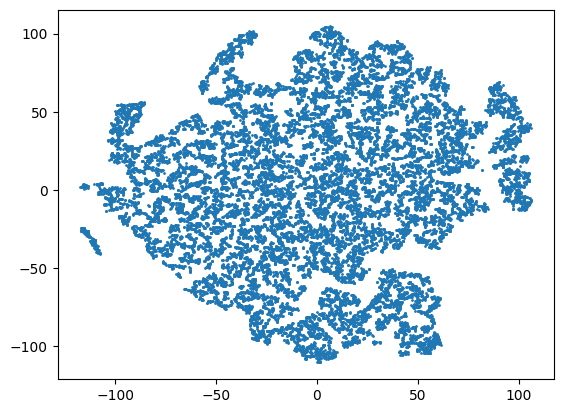

In [19]:
n_pcs_used         = elbow       # how many PCs go into t-SNE (1 to n_pc)
perplexity         = 30          # roughly how many neighbours each point considers (5–50)
early_exaggeration = 12          # how hard clusters are pushed apart at the start (≥1; try 4–30)
learning_rate      = "auto"      # step size: "auto" or a number (10–1000)
max_iter           = 1000        # number of iterations (must be at least 250)
init               = "random"    # starting layout: "pca" or "random"
random_state       = 0           # same number = same map every run; change it to see another layout

T = TSNE(n_components=2, perplexity=perplexity, early_exaggeration=early_exaggeration,
         learning_rate=learning_rate, max_iter=max_iter, init=init,
         random_state=random_state).fit_transform(P[:, :n_pcs_used])
plt.scatter(T[:, 0], T[:, 1], s=1)

## 14. k-means on the t-SNE map

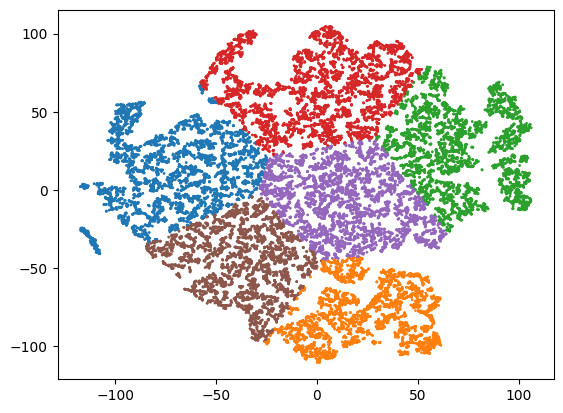

In [20]:
k = 6
labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(T)     # try .fit_predict(P[:, :n_pcs_used]) and compare!
plt.scatter(T[:, 0], T[:, 1], s=1, c=labels, cmap="tab10", vmin=0, vmax=9)

## 15. Original image vs classification map

Text(0.5, 1.0, 'k-means, k = 6')

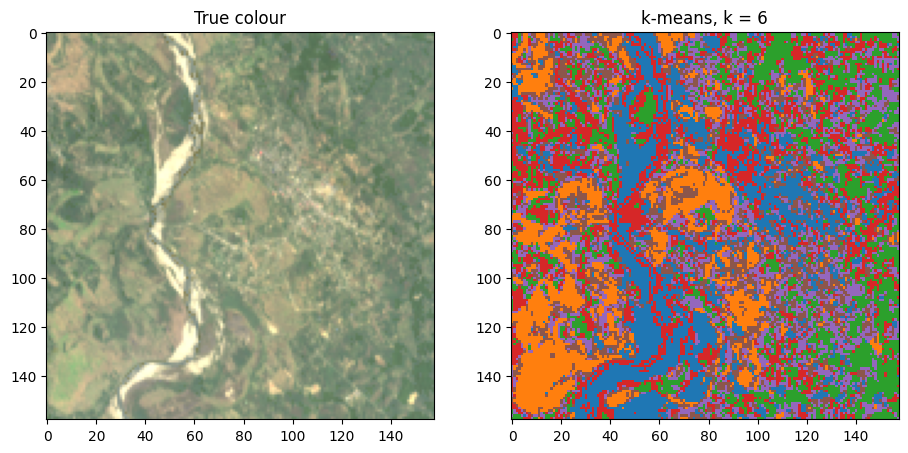

In [23]:
plt.figure(figsize=(11, 7))
plt.subplot(1, 2, 1); plt.imshow(stretch(cube[:, :, [band(650), band(560), band(470)]])); plt.title("True colour")
plt.subplot(1, 2, 2); plt.imshow(labels.reshape(size, size), cmap="tab10", vmin=0, vmax=9, interpolation="nearest"); plt.title(f"k-means, k = {k}")

## 16. What is each class? Mean spectrum per cluster
Same colours as the map. Use the shapes (red edge, SWIR clay/water features, …) to name each class.

Text(0, 0.5, 'Mean reflectance')

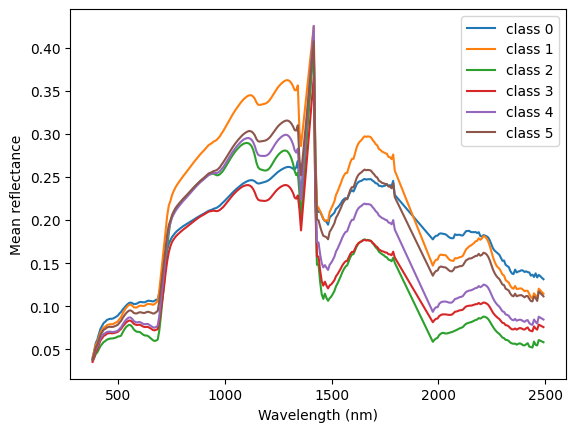

In [24]:
for i in range(k): plt.plot(wl, X[labels == i].mean(0), color=plt.cm.tab10(i), label=f"class {i}")
plt.legend(); plt.xlabel("Wavelength (nm)"); plt.ylabel("Mean reflectance")